In [14]:
!python predict.py test1A LLMCurators test1A

img_0001.jpg -> sp-02
img_0002.jpg -> sp-05
img_0003.jpg -> sp-02
img_0004.jpg -> sp-02
img_0005.jpg -> sp-02
img_0006.jpg -> sp-01
img_0007.jpg -> sp-03
img_0008.jpg -> sp-04
img_0009.jpg -> sp-01
img_0010.jpg -> sp-05
img_0011.jpg -> sp-05
img_0012.jpg -> sp-05
img_0013.jpg -> sp-01
img_0014.jpg -> sp-03
img_0015.jpg -> sp-02
img_0016.jpg -> sp-05
img_0017.jpg -> sp-03
img_0018.jpg -> sp-01
img_0019.jpg -> sp-05
img_0020.jpg -> sp-02
img_0021.jpg -> sp-02
img_0022.jpg -> sp-02
img_0023.jpg -> sp-01
img_0024.jpg -> sp-05
img_0025.jpg -> sp-03
img_0026.jpg -> sp-04
img_0027.jpg -> sp-03
img_0028.jpg -> sp-01
img_0029.jpg -> sp-01
img_0030.jpg -> sp-04
img_0031.jpg -> sp-05
img_0032.jpg -> sp-05
img_0033.jpg -> sp-03
img_0034.jpg -> sp-04
img_0035.jpg -> sp-02
img_0036.jpg -> sp-05
img_0037.jpg -> sp-05
img_0038.jpg -> sp-01
img_0039.jpg -> sp-03
img_0040.jpg -> sp-01
img_0041.jpg -> sp-02
img_0042.jpg -> sp-02
img_0043.jpg -> sp-04
img_0044.jpg -> sp-05
img_0045.jpg -> sp-05
img_0046.j

In [15]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

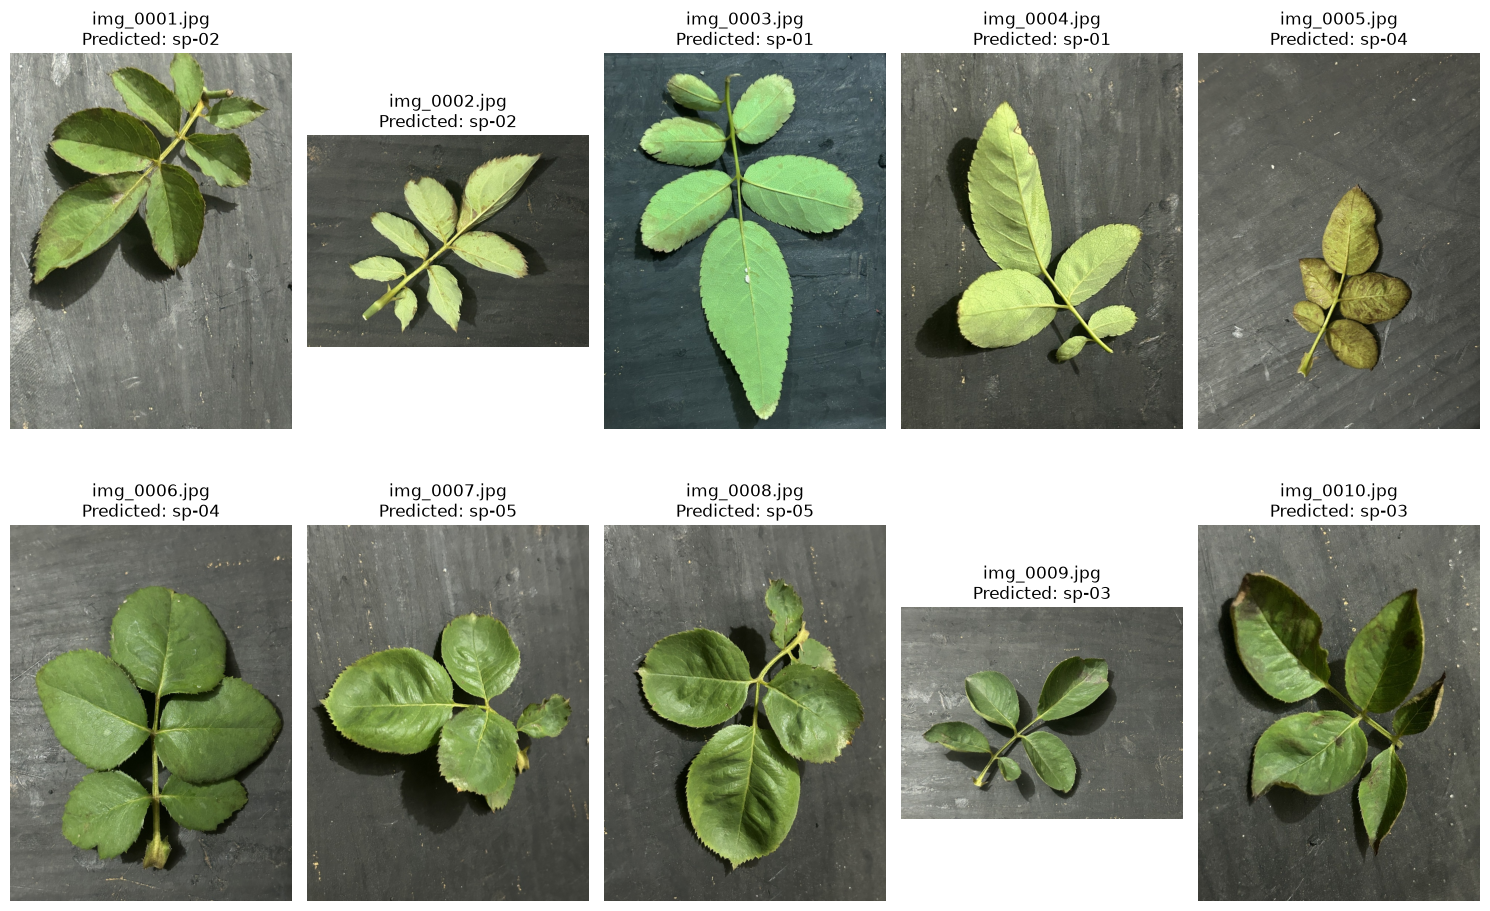

In [5]:
folder = "demo_test_2"

df = pd.read_csv("LLMCurators_prediction_test2.csv")

plt.figure(figsize=(15, 10))

for i, row in df.iterrows():

    image_path = os.path.join(folder, row["file"])

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)

    plt.title(
        f'{row["file"]}\nPredicted: {row["predicted"]}'
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

df1 = pd.read_csv("LLMCurators_prediction_test1.csv")
df2 = pd.read_csv("LLMCurators_prediction_test2.csv")

all_predictions = pd.concat([df1, df2], ignore_index=True)

print("Total images:", len(all_predictions))

print("\nSpecies prediction count:")
print(all_predictions["predicted"].value_counts())

Total images: 20

Species prediction count:
predicted
sp-01    4
sp-02    4
sp-03    4
sp-04    4
sp-05    4
Name: count, dtype: int64


In [8]:
!python check_submission.py LLMCurators_prediction_test2.csv demo_test_2 --model leaf_model.pth

file    : LLMCurators_prediction_test2.csv
team    : LLMCurators
test set: test2
columns : ['file', 'predicted']
rows    : 10
images in folder: 10
every test image has exactly one prediction

prediction counts:
predicted
sp-01    2
sp-02    2
sp-03    2
sp-04    2
sp-05    2

READY - this file is valid.


In [9]:
import hashlib, os

for path in ["model.pt", "leaf_model.pth"]:
    if os.path.exists(path):
        h = hashlib.sha256(open(path, "rb").read()).hexdigest()
        print(path, "| size MB:", round(os.path.getsize(path) / 1e6, 1), "| sha256:", h[:16])

model.pt | size MB: 44.8 | sha256: 9c04843e5310fa0d
leaf_model.pth | size MB: 44.8 | sha256: c71f81e712413081


In [11]:
!python check_submission.py LLMCurators_prediction_test2.csv demo_test_2 --model leaf_model.pth

file    : LLMCurators_prediction_test2.csv
team    : LLMCurators
test set: test2
columns : ['file', 'predicted']
rows    : 10
images in folder: 10
every test image has exactly one prediction

prediction counts:
predicted
sp-01    2
sp-02    2
sp-03    2
sp-04    2
sp-05    2

READY - this file is valid.


In [12]:
import torch

model1 = torch.load("model.pt", map_location="cpu", weights_only=True)
model2 = torch.load("leaf_model.pth", map_location="cpu", weights_only=True)

print("Model 1 keys:", model1.keys())
print("Model 2 keys:", model2.keys())

Model 1 keys: odict_keys(['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.1.conv1.weight', 'layer1.1.bn1.weight', 'layer1.1.bn1.bias', 'layer1.1.bn1.running_mean', 'layer1.1.bn1.running_var', 'layer1.1.bn1.num_batches_tracked', 'layer1.1.conv2.weight', 'layer1.1.bn2.weight', 'layer1.1.bn2.bias', 'layer1.1.bn2.running_mean', 'layer1.1.bn2.running_var', 'layer1.1.bn2.num_batches_tracked', 'layer2.0.conv1.weight', 'layer2.0.bn1.weight', 'layer2.0.bn1.bias', 'layer2.0.bn1.running_mean', 'layer2.0.bn1.running_var', 'layer2.0.bn1.num_batches_tracked', 'layer2.0.conv2.weight', 'layer2.0.bn2.weight', 'layer2.

In [15]:
import hashlib

MODEL_PATH = "leaf_model.pth"

with open(MODEL_PATH, "rb") as f:
    model_hash = hashlib.sha256(f.read()).hexdigest()

MODEL_ID = "MACRODATA_RESNET18_" + model_hash[:12].upper()

print("MODEL ID:", MODEL_ID)

MODEL ID: MACRODATA_RESNET18_C71F81E71241


In [16]:
import torchvision.models as models

# Load with ImageNet pretrained weights
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Or string equivalent
model = models.resnet18(weights='IMAGENET1K_V1')